In [1]:
# ============================================================
# CELL 1 — Imports and configuration
# ============================================================
# Baker Hughes Rig Count Tracker
# Source  : Baker Hughes (weekly Excel download)
# Release : Every Friday ~1:00pm ET
#
# Why rig count matters:
#   Leading indicator — oil rigs today -> production in 6-9mo
#   Gas rigs today    -> gas supply in 6-9 months
#   Permian share     -> where US growth is concentrated
#   WTI price drives rig count with ~16-26 week lag
# ─────────────────────────────────────────────────────────────

# Standard library
import sys
import io
import os
from pathlib import Path
import datetime as dt

# Filepath handling
import glob

# Data handling
import pandas as pd
import numpy as np

# Excel parsing
import openpyxl

# HTTP download
import requests

# Market data
import yfinance as yf

# Visualization
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
from matplotlib.gridspec import GridSpec

# Display settings
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
plt.style.use("seaborn-v0_8-darkgrid")

# ── Path setup ────────────────────────────────────────────────
PROJECT_ROOT = Path.cwd().parent
CHART_DIR    = PROJECT_ROOT / "charts"
DATA_DIR     = PROJECT_ROOT / "data"

# ── Baker Hughes URLs ─────────────────────────────────────────
# North America rotary rig count workbook
# URL verified April 2026 — may change; use manual fallback
# if download fails
BH_NA_URL = (
    "https://rigcount.bakerhughes.com/static-files/13045a43-b42d-493d-b4c7-cb408e620334"
)

# Manual fallback path — if auto-download fails:
#   1. Go to bakerhughes.com/rig-count
#   2. Download "North America Rotary Rig Count" Excel
#   3. Save as the path below
MANUAL_FALLBACK = DATA_DIR / "BH_rig_count_manual.xlsx"

# Auto-download save path
BH_CACHE = DATA_DIR / "BH_rig_count_latest.xlsx"

# ── WTI price cache ───────────────────────────────────────────
# Reuse cache from Tools 2 and 4
WTI_CACHE = DATA_DIR / "wti_price_cache.csv"

# ── Date configuration ────────────────────────────────────────
END_DATE    = dt.date.today()
START_DATE  = END_DATE - dt.timedelta(days=365 * 4)  # 4yr history

# ── Key basin names to extract ────────────────────────────────
# These are the BH sheet column name fragments we search for
# BH occasionally renames columns — we match by keyword
KEY_BASINS = {
    "Permian"         : ["permian"],
    "Eagle Ford"      : ["eagle ford", "eagleford"],
    "Haynesville"     : ["haynesville"],
    "Marcellus"       : ["marcellus"],
    "DJ/Niobrara"     : ["dj", "niobrara"],
    "Williston"       : ["williston", "bakken"],
    "Anadarko"        : ["anadarko", "scoop", "stack"],
}

print("=" * 58)
print("Tool 6 — Baker Hughes Rig Count Tracker")
print("=" * 58)
print(f"Run date       : {END_DATE}")
print(f"BH URL         : {BH_NA_URL[:50]}...")
print(f"Manual fallback: {MANUAL_FALLBACK.name}")
print(f"WTI cache      : {WTI_CACHE.name}")
print(f"History        : {START_DATE} -> {END_DATE}")
print("=" * 58)
print()
print("Key basins tracked:")
for basin, keywords in KEY_BASINS.items():
    print(f"  {basin:<18} (keywords: {keywords})")

Tool 6 — Baker Hughes Rig Count Tracker
Run date       : 2026-10-10
BH URL         : https://rigcount.bakerhughes.com/static-files/1304...
Manual fallback: BH_rig_count_manual.xlsx
WTI cache      : wti_price_cache.csv
History        : 2022-10-11 -> 2026-10-10

Key basins tracked:
  Permian            (keywords: ['permian'])
  Eagle Ford         (keywords: ['eagle ford', 'eagleford'])
  Haynesville        (keywords: ['haynesville'])
  Marcellus          (keywords: ['marcellus'])
  DJ/Niobrara        (keywords: ['dj', 'niobrara'])
  Williston          (keywords: ['williston', 'bakken'])
  Anadarko           (keywords: ['anadarko', 'scoop', 'stack'])


In [2]:
# ============================================================
# CELL 2 — Download Baker Hughes Excel workbook
# ============================================================
# Attempts auto-download from BH website.
# Falls back to manual file if download fails.
# Prints all sheet names for verification.
# ─────────────────────────────────────────────────────────────

def load_bh_workbook() -> tuple:
    """
    Load the BH North America rig count workbook.
    Manual download is the primary and only source.
    Auto-download disabled — BH URL changes weekly.
    
    Workflow: download from rigcount.bakerhughes.com/na-rig-count
    and save as BH_rig_count_manual.xlsx each Friday.
    """
    if MANUAL_FALLBACK.exists():
        print(f"  Loading manual file: {MANUAL_FALLBACK.name}")
        load_path = MANUAL_FALLBACK
    elif BH_CACHE.exists():
        print(f"  Loading cached auto-download: {BH_CACHE.name}")
        print(f"  Warning: this may be stale — download fresh file")
        load_path = BH_CACHE
    else:
        print("=" * 58)
        print("  !! NO BH DATA FILE FOUND")
        print("=" * 58)
        print(f"""
            To resolve:
            1. Go to: https://rigcount.bakerhughes.com/na-rig-count
            2. Download 'North America Rig Count Report' Excel
            3. Save as: {MANUAL_FALLBACK}
            4. Re-run this cell
                    """)
        raise FileNotFoundError("No Baker Hughes data file available.")

    xf = pd.ExcelFile(load_path, engine="openpyxl")
    print(f"  File size   : {load_path.stat().st_size/1024:.0f} KB")
    print(f"  Sheet count : {len(xf.sheet_names)}")
    print()
    print("  Sheet names:")
    for i, name in enumerate(xf.sheet_names):
        print(f"    {i:2d}. '{name}'")

    return xf, load_path

# ── Load the workbook ─────────────────────────────────────────
xf, loaded_excel_path = load_bh_workbook()

  Loading manual file: BH_rig_count_manual.xlsx
  File size   : 7864 KB
  Sheet count : 6

  Sheet names:
     0. 'NAM Summary'
     1. 'NAM Breakdown'
     2. 'NAM Yearly'
     3. 'NAM Quarterly'
     4. 'NAM Monthly'
     5. 'NAM Weekly'


In [3]:
# ============================================================
# CELL 3 — Parse US rig count (archive + current combined)
# ============================================================
# Data strategy:
#   Archive file : 2013-Aug 2025 (one-time historical backfill)
#   Current file : 2024-present  (updated weekly)
#   Combined     : saved to CSV cache after first parse
#                  loads from cache on all subsequent runs
#
# On first run  : parses both Excel files (~30 sec)
# On later runs : loads CSV cache (~1 sec)
#
# To refresh after weekly BH download:
#   1. Save new BH Excel as BH_rig_count_manual.xlsx
#   2. Delete BH_weekly_us_combined.csv and
#              BH_monthly_us_combined.csv
#   3. Rerun this cell — cache rebuilds automatically
# ─────────────────────────────────────────────────────────────

HEADER_ROW = 10

# ── Cache paths ───────────────────────────────────────────────
WEEKLY_COMBINED_CACHE  = (
    DATA_DIR / "BH_weekly_us_combined.csv"
)
MONTHLY_COMBINED_CACHE = (
    DATA_DIR / "BH_monthly_us_combined.csv"
)
ARCHIVE_PATH = (
    DATA_DIR / "08-29-2025 North America Rig Count Report.xlsx"
)

# ── Auto-clear stale cache if new Excel is available ─────────
# The combined CSVs are rebuilt each time the source Excel
# changes. If BH_rig_count_manual.xlsx is newer than the
# cache, delete the cache to force a rebuild.
# This means you only need to:
#   1. Save new BH Excel as BH_rig_count_manual.xlsx
#   2. Rerun Cell 3 — cache clears and rebuilds automatically

def _cache_is_stale() -> bool:
    if not WEEKLY_COMBINED_CACHE.exists():
        return True
    if not MONTHLY_COMBINED_CACHE.exists():
        return True
    # Compare the loaded workbook file against the cache
    # This correctly handles both manual and auto-download paths
    loaded_file = loaded_excel_path  # set by Cell 2's load_bh_workbook()
    if not loaded_file.exists():
        return False
    excel_mtime = loaded_file.stat().st_mtime
    cache_mtime = WEEKLY_COMBINED_CACHE.stat().st_mtime
    return excel_mtime > cache_mtime

if _cache_is_stale():
    print("  New Excel detected or cache missing — clearing cache...")
    for cache_file in [WEEKLY_COMBINED_CACHE,
                       MONTHLY_COMBINED_CACHE]:
        if cache_file.exists():
            os.remove(cache_file)
            print(f"  Deleted: {cache_file.name}")
    print()
else:
    print("  Cache is current — will load from CSV")
    print()


# ── Helper: parse US weekly from one workbook ─────────────────
def parse_us_weekly(xf: pd.ExcelFile) -> pd.DataFrame:
    df = pd.read_excel(
        xf, sheet_name="NAM Weekly", header=HEADER_ROW
    )
    df = df.dropna(subset=["Country"]).copy()
    df = df[df["Country"] == "UNITED STATES"].copy()

    # Find publish date column
    date_col = None
    for col in df.columns:
        if "publish" in str(col).lower():
            date_col = col
            break
    if date_col is None:
        raise ValueError(
            "Could not find publish date column in NAM Weekly. "
            f"Columns: {df.columns.tolist()}"
        )

    df["date"] = pd.to_datetime(df[date_col], errors="coerce")
    df["Rig Count Value"] = pd.to_numeric(
        df["Rig Count Value"], errors="coerce"
    ).fillna(0)
    return df.dropna(subset=["date"])


# ── Helper: parse US monthly from one workbook ────────────────
def parse_us_monthly(xf: pd.ExcelFile) -> pd.DataFrame:
    df = pd.read_excel(
        xf,
        sheet_name = "NAM Monthly",
        header     = HEADER_ROW,
        usecols    = range(11),
    )
    df = df.dropna(subset=["Country"]).copy()
    df = df[df["Country"] == "UNITED STATES"].copy()

    df["Rig Count Value"] = pd.to_numeric(
        df["Rig Count Value"], errors="coerce"
    ).fillna(0)
    df["Year"]  = df["Year"].astype(int)
    df["Month"] = df["Month"].astype(int)
    df["date"]  = pd.to_datetime(
        df["Year"].astype(str) + "-" +
        df["Month"].astype(str) + "-01"
    )
    return df


# ── Main load function ────────────────────────────────────────
def load_or_build_combined(
    weekly_cache:  Path,
    monthly_cache: Path,
    xf_current:    pd.ExcelFile,
    archive_path:  Path,
) -> tuple:
    """
    Returns (df_us_w, df_us_m) as long-format DataFrames.
    Loads from CSV cache if available, otherwise parses
    Excel files and saves cache.
    """

    # ── Fast path: load from cache ────────────────────────────
    if weekly_cache.exists() and monthly_cache.exists():
        print("  Cache found — loading combined data...")
        df_w = pd.read_csv(
            weekly_cache, parse_dates=["date"]
        )
        df_m = pd.read_csv(
            monthly_cache, parse_dates=["date"]
        )
        print(f"  Weekly rows  : {len(df_w):,}")
        print(f"  Monthly rows : {len(df_m):,}")
        print(f"  Weekly date range : "
              f"{df_w['date'].min().date()} -> "
              f"{df_w['date'].max().date()}")
        return df_w, df_m

    # ── Slow path: parse from Excel ───────────────────────────
    print("  No cache found — parsing Excel files...")
    print()

    # Parse current file
    print("  [1/2] Current workbook...")
    df_curr_w = parse_us_weekly(xf_current)
    df_curr_m = parse_us_monthly(xf_current)
    print(f"    Weekly rows  : {len(df_curr_w):,}")
    print(f"    Monthly rows : {len(df_curr_m):,}")
    print(f"    Date range   : "
          f"{df_curr_w['date'].min().date()} -> "
          f"{df_curr_w['date'].max().date()}")

    # Parse archive if available
    if archive_path.exists():
        print()
        print("  [2/2] Archive workbook...")
        xf_arch   = pd.ExcelFile(
            archive_path, engine="openpyxl"
        )
        df_arch_w = parse_us_weekly(xf_arch)
        df_arch_m = parse_us_monthly(xf_arch)
        print(f"    Weekly rows  : {len(df_arch_w):,}")
        print(f"    Monthly rows : {len(df_arch_m):,}")
        print(f"    Date range   : "
              f"{df_arch_w['date'].min().date()} -> "
              f"{df_arch_w['date'].max().date()}")

        # Concatenate archive + current
        # Sort by date then deduplicate keeping the last
        # occurrence — current file is authoritative for
        # any overlapping dates (Jan 2024-Aug 2025)
        df_w = (
            pd.concat([df_arch_w, df_curr_w],
                      ignore_index=True)
            .sort_values("date")
        )
        df_m = (
            pd.concat([df_arch_m, df_curr_m],
                      ignore_index=True)
            .sort_values("date")
        )

        # ── Deduplicate overlap period ────────────────────────────────
        # Archive and current file overlap Jan 2024 - Aug 2025.
        # For any date present in both, keep current file records only.
        # Strategy: tag rows by source, then drop archive rows
        # for dates that also exist in the current file.

        # Tag sources before concat
        df_arch_w["_source"]  = "archive"
        df_curr_w["_source"]  = "current"
        df_arch_m["_source"]  = "archive"
        df_curr_m["_source"]  = "current"

        # Combine
        df_w_raw = pd.concat(
            [df_arch_w, df_curr_w], ignore_index=True
        ).sort_values("date")

        df_m_raw = pd.concat(
            [df_arch_m, df_curr_m], ignore_index=True
        ).sort_values("date")

        # Find dates present in current file
        current_w_dates = set(
            df_curr_w["date"].dt.normalize().unique()
        )
        current_m_dates = set(
            df_curr_m["date"].dt.normalize().unique()
        )

        # Drop archive rows for dates covered by current file
        df_w = df_w_raw[
            ~(
                (df_w_raw["_source"] == "archive") &
                (df_w_raw["date"].dt.normalize()
                .isin(current_w_dates))
            )
        ].drop(columns=["_source"]).reset_index(drop=True)

        df_m = df_m_raw[
            ~(
                (df_m_raw["_source"] == "archive") &
                (df_m_raw["date"].dt.normalize()
                .isin(current_m_dates))
            )
        ].drop(columns=["_source"]).reset_index(drop=True)

        print(f"  After dedup:")
        print(f"    Weekly rows  : {len(df_w):,}  "
            f"(was {len(df_w_raw):,})")
        print(f"    Monthly rows : {len(df_m):,}  "
            f"(was {len(df_m_raw):,})")

    else:
        print()
        print("  [2/2] Archive not found — current file only")
        print(f"        Expected: {archive_path.name}")
        df_w = df_curr_w.sort_values("date")
        df_m = df_curr_m.sort_values("date")

    # ── Save minimal columns to cache ─────────────────────────
    w_cols = ["date", "DrillFor", "Basin", "Rig Count Value"]
    m_cols = ["date", "Year", "Month", "Basin",
              "DrillFor", "Rig Count Value"]

    w_cols = [c for c in w_cols if c in df_w.columns]
    m_cols = [c for c in m_cols if c in df_m.columns]

    df_w[w_cols].to_csv(weekly_cache,  index=False)
    df_m[m_cols].to_csv(monthly_cache, index=False)

    print()
    print(f"  Saved -> {weekly_cache.name}")
    print(f"  Saved -> {monthly_cache.name}")
    print()
    print(f"  Combined weekly rows  : {len(df_w):,}")
    print(f"  Combined monthly rows : {len(df_m):,}")
    print(f"  Full date range       : "
          f"{df_w['date'].min().date()} -> "
          f"{df_w['date'].max().date()}")

    return df_w[w_cols], df_m[m_cols]


# ── Load data ─────────────────────────────────────────────────
print("=" * 58)
print("Loading BH rig count data...")
print("=" * 58)
df_us_w, df_us_m = load_or_build_combined(
    weekly_cache  = WEEKLY_COMBINED_CACHE,
    monthly_cache = MONTHLY_COMBINED_CACHE,
    xf_current    = xf,
    archive_path  = ARCHIVE_PATH,
)
print()

# ── Aggregate weekly: total and by type ──────────────────────
print("Aggregating weekly rig count...")

df_total_w = (
    df_us_w.groupby("date")["Rig Count Value"]
    .sum()
    .reset_index()
    .rename(columns={"Rig Count Value": "total_rigs"})
    .sort_values("date")
    .reset_index(drop=True)
)

df_type_w = (
    df_us_w.groupby(["date", "DrillFor"])["Rig Count Value"]
    .sum()
    .reset_index()
    .pivot(index="date", columns="DrillFor",
           values="Rig Count Value")
    .reset_index()
)
df_type_w.columns.name = None
col_map = {
    "Oil"          : "oil_rigs",
    "Gas"          : "gas_rigs",
    "Miscellaneous": "misc_rigs",
}
df_type_w = (
    df_type_w
    .rename(columns=col_map)
    .sort_values("date")
    .reset_index(drop=True)
)

df_rigs_w = (
    df_total_w
    .merge(df_type_w, on="date", how="left")
    .sort_values("date")
    .reset_index(drop=True)
)

# ── Aggregate monthly: basin breakdown ───────────────────────
print("Aggregating monthly basin breakdown...")

basin_map = {
    "Permian"    : "Permian",
    "Eagle Ford" : "Eagle Ford",
    "Haynesville": "Haynesville",
    "Marcellus"  : "Marcellus",
    "DJ-Niobrara": "DJ/Niobrara",
    "Williston"  : "Williston",
    "Utica"      : "Utica",
}

df_basins_raw = df_us_m[
    df_us_m["Basin"].isin(basin_map.keys())
].copy()
df_basins_raw["Basin"] = df_basins_raw["Basin"].map(basin_map)

df_basins = (
    df_basins_raw
    .groupby(["date", "Basin"])["Rig Count Value"]
    .sum()
    .reset_index()
    .pivot(index="date", columns="Basin",
           values="Rig Count Value")
    .reset_index()
)
df_basins.columns.name = None
df_basins = (
    df_basins
    .sort_values("date")
    .reset_index(drop=True)
)

# ── Rolling averages ──────────────────────────────────────────
df_rigs_w["total_4wk_avg"] = (
    df_rigs_w["total_rigs"].rolling(4, min_periods=2).mean()
)
df_rigs_w["oil_4wk_avg"] = (
    df_rigs_w["oil_rigs"].rolling(4, min_periods=2).mean()
)

# ── YoY (52-week shift on weekly series) ─────────────────────
df_rigs_w["total_yoy"] = (
    df_rigs_w["total_rigs"]
    - df_rigs_w["total_rigs"].shift(52)
)
df_rigs_w["oil_yoy"] = (
    df_rigs_w["oil_rigs"]
    - df_rigs_w["oil_rigs"].shift(52)
)

# ── Summary ───────────────────────────────────────────────────
latest_w    = df_rigs_w.iloc[-1]
latest_date = df_rigs_w["date"].max().strftime("%B %d, %Y")

print()
print("=" * 58)
print("Rig count data ready")
print("=" * 58)
print(f"  Weekly obs     : {len(df_rigs_w)}")
print(f"  Date range     : "
      f"{df_rigs_w['date'].min().strftime('%b %Y')} -> "
      f"{df_rigs_w['date'].max().strftime('%b %Y')}")
print(f"  Latest week    : {latest_date}")
print()
print(f"  Total rigs     : {latest_w['total_rigs']:.0f}")
print(f"  Oil rigs       : {latest_w['oil_rigs']:.0f}")
print(f"  Gas rigs       : {latest_w['gas_rigs']:.0f}")
print(f"  Misc rigs      : {latest_w['misc_rigs']:.0f}")
print(f"  4-week avg     : {latest_w['total_4wk_avg']:.0f}")
if not pd.isna(latest_w["total_yoy"]):
    print(f"  YoY change     : {latest_w['total_yoy']:+.0f} rigs")
print()
print("Key basins (latest month):")
latest_basin = df_basins.iloc[-1]
for basin in basin_map.values():
    if basin in df_basins.columns:
        print(f"  {basin:<18}: "
              f"{latest_basin[basin]:.0f} rigs")
print("=" * 58)

  New Excel detected or cache missing — clearing cache...
  Deleted: BH_weekly_us_combined.csv
  Deleted: BH_monthly_us_combined.csv

Loading BH rig count data...
  No cache found — parsing Excel files...

  [1/2] Current workbook...


c:\Users\mackt\.conda\envs\oilgas\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
c:\Users\mackt\.conda\envs\oilgas\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


    Weekly rows  : 24,116
    Monthly rows : 6,241
    Date range   : 2024-01-05 -> 2026-10-09

  [2/2] Archive workbook...


c:\Users\mackt\.conda\envs\oilgas\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
c:\Users\mackt\.conda\envs\oilgas\Lib\site-packages\openpyxl\worksheet\_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


    Weekly rows  : 154,126
    Monthly rows : 42,478
    Date range   : 2013-01-04 -> 2025-08-29
  After dedup:
    Weekly rows  : 164,249  (was 178,242)
    Monthly rows : 45,174  (was 48,719)

  Saved -> BH_weekly_us_combined.csv
  Saved -> BH_monthly_us_combined.csv

  Combined weekly rows  : 164,249
  Combined monthly rows : 45,174
  Full date range       : 2013-01-04 -> 2026-10-09

Aggregating weekly rig count...
Aggregating monthly basin breakdown...

Rig count data ready
  Weekly obs     : 719
  Date range     : Jan 2013 -> Oct 2026
  Latest week    : October 09, 2026

  Total rigs     : 603
  Oil rigs       : 462
  Gas rigs       : 132
  Misc rigs      : 9
  4-week avg     : 599
  YoY change     : +56 rigs

Key basins (latest month):
  Permian           : 272 rigs
  Eagle Ford        : 49 rigs
  Haynesville       : 56 rigs
  Marcellus         : 23 rigs
  DJ/Niobrara       : 10 rigs
  Williston         : 35 rigs
  Utica             : 10 rigs


In [4]:
# ============================================================
# CELL 4 — Fetch WTI price history for overlay
# ============================================================
# Reuses the WTI price cache built by Tools 2 and 4.
# Resamples daily prices to weekly (Friday close) to
# align with Baker Hughes weekly publish dates.
#
# WTI price leads rig count by approximately 16-26 weeks.
# We overlay them on the same chart to visualize the lag.
# ─────────────────────────────────────────────────────────────

print("Loading WTI price data...")

# ── Load from cache ───────────────────────────────────────────
if WTI_CACHE.exists():
    df_wti_daily = pd.read_csv(
        WTI_CACHE, parse_dates=["date"]
    )
    # Handle both 'price' and 'wti' column names
    if "price" in df_wti_daily.columns:
        df_wti_daily = df_wti_daily.rename(
            columns={"price": "wti"}
        )
    df_wti_daily = (df_wti_daily
                    .sort_values("date")
                    .reset_index(drop=True))
    print(f"  Loaded from cache : {len(df_wti_daily):,} days")
    print(f"  Date range        : "
          f"{df_wti_daily['date'].min().date()} -> "
          f"{df_wti_daily['date'].max().date()}")
    print(f"  Latest WTI        : "
          f"${df_wti_daily['wti'].iloc[-1]:.2f}/bbl")
else:
    print("  WTI cache not found — downloading...")
    raw = yf.download(
        "CL=F", start="2022-01-01",
        auto_adjust=True, progress=False
    )
    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)
    df_wti_daily = (raw[["Close"]]
                    .rename(columns={"Close": "wti"})
                    .reset_index()
                    .rename(columns={"Date": "date",
                                     "index": "date"}))
    df_wti_daily.to_csv(WTI_CACHE, index=False)
    print(f"  Downloaded and cached: {len(df_wti_daily):,} days")

# ── Filter to relevant date range ─────────────────────────────
df_wti_filtered = df_wti_daily[
    df_wti_daily["date"] >= pd.Timestamp(START_DATE)
].copy()

# ── Resample to weekly Friday close ───────────────────────────
# Align with BH weekly publish dates (Fridays)
df_wti_weekly = (
    df_wti_filtered
    .set_index("date")
    .resample("W-FRI")["wti"]
    .last()
    .reset_index()
    .dropna(subset=["wti"])
)

# ── Rolling statistics for context ────────────────────────────
df_wti_weekly["wti_52w_high"] = (
    df_wti_weekly["wti"].rolling(52, min_periods=20).max()
)
df_wti_weekly["wti_52w_low"] = (
    df_wti_weekly["wti"].rolling(52, min_periods=20).min()
)
df_wti_weekly["wti_ma26"] = (
    df_wti_weekly["wti"].rolling(26, min_periods=10).mean()
)

latest_wti    = df_wti_weekly["wti"].iloc[-1]
latest_wti_dt = df_wti_weekly["date"].max().strftime("%B %d, %Y")

print()
print("=" * 58)
print("WTI weekly data ready")
print("=" * 58)
print(f"  Weekly obs     : {len(df_wti_weekly)}")
print(f"  Date range     : "
      f"{df_wti_weekly['date'].min().date()} -> "
      f"{df_wti_weekly['date'].max().date()}")
print(f"  Latest WTI     : ${latest_wti:.2f}/bbl  "
      f"({latest_wti_dt})")
print(f"  52-week high   : "
      f"${df_wti_weekly['wti_52w_high'].iloc[-1]:.2f}/bbl")
print(f"  52-week low    : "
      f"${df_wti_weekly['wti_52w_low'].iloc[-1]:.2f}/bbl")
print("=" * 58)

Loading WTI price data...
  Loaded from cache : 4,976 days
  Date range        : 2007-01-02 -> 2026-10-09
  Latest WTI        : $91.85/bbl

WTI weekly data ready
  Weekly obs     : 209
  Date range     : 2022-10-14 -> 2026-10-09
  Latest WTI     : $91.85/bbl  (October 09, 2026)
  52-week high   : $111.54/bbl
  52-week low    : $56.66/bbl


In [5]:
# ============================================================
# CELL 5 — Merge rig count with WTI and compute analytics
# ============================================================
# Updated from initial version:
#   YoY uses date-based matching (robust to series gaps)
#   Correlation uses rolling 3-year window to capture
#   current market regime rather than full history
#   (full history correlation is distorted by 2020 COVID
#   collapse which broke normal WTI-rig relationship)
# ─────────────────────────────────────────────────────────────

# ── Merge on date using merge_asof ────────────────────────────
df_merged = pd.merge_asof(
    df_rigs_w.sort_values("date"),
    df_wti_weekly[["date","wti","wti_ma26",
                   "wti_52w_high","wti_52w_low"]]
    .sort_values("date"),
    on        = "date",
    direction = "nearest",
    tolerance = pd.Timedelta(days=3),
)
df_merged = df_merged.sort_values("date").reset_index(drop=True)

# ── Week-on-week changes ──────────────────────────────────────
for col in ["total_rigs", "oil_rigs", "gas_rigs"]:
    df_merged[f"{col}_wow"] = (
        df_merged[col] - df_merged[col].shift(1)
    )

# ── 52-week rig count range ───────────────────────────────────
df_merged["total_52w_high"] = (
    df_merged["total_rigs"].rolling(52, min_periods=20).max()
)
df_merged["total_52w_low"] = (
    df_merged["total_rigs"].rolling(52, min_periods=20).min()
)
df_merged["oil_52w_high"] = (
    df_merged["oil_rigs"].rolling(52, min_periods=20).max()
)
df_merged["oil_52w_low"] = (
    df_merged["oil_rigs"].rolling(52, min_periods=20).min()
)

# ── YoY: date-based matching (robust to series gaps) ─────────
# Build a lookup version of df_merged shifted back 365 days
# then merge_asof to find the closest prior-year observation
df_prior_year = df_merged[["date","total_rigs","oil_rigs"]].copy()
df_prior_year["date_lookup"] = (
    df_prior_year["date"] + pd.Timedelta(days=365)
)

df_yoy = pd.merge_asof(
    df_merged[["date","total_rigs","oil_rigs"]]
    .rename(columns={
        "total_rigs": "total_now",
        "oil_rigs"  : "oil_now",
    })
    .sort_values("date"),
    df_prior_year[["date_lookup","total_rigs","oil_rigs"]]
    .rename(columns={
        "date_lookup": "date",
        "total_rigs" : "total_prior",
        "oil_rigs"   : "oil_prior",
    })
    .sort_values("date"),
    on        = "date",
    direction = "nearest",
    tolerance = pd.Timedelta(days=10),
)

df_merged["total_yoy"] = (
    df_yoy["total_now"].values - df_yoy["total_prior"].values
)
df_merged["oil_yoy"] = (
    df_yoy["oil_now"].values - df_yoy["oil_prior"].values
)

# ── Permian share ─────────────────────────────────────────────
if "Permian" in df_basins.columns:
    df_basins_clean = (
        df_basins[["date","Permian"]
                  + [c for c in df_basins.columns
                     if c not in ["date","Permian"]]]
        .drop_duplicates(subset=["date"])
        .reset_index(drop=True)
    )
    df_merged = pd.merge_asof(
        df_merged.sort_values("date").reset_index(drop=True),
        df_basins_clean.sort_values("date").reset_index(drop=True),
        on        = "date",
        direction = "backward",
        tolerance = pd.Timedelta(days=35),
    )
    df_merged["permian_share"] = (
        df_merged["Permian"] / df_merged["oil_rigs"] * 100
    )

# ── Lagged WTI correlation ────────────────────────────────────
# Two approaches:
#   Full history : shows structural relationship since 2013
#                  but distorted by 2020 COVID anomaly
#   Rolling 3yr  : captures current market regime
#                  (post-COVID shale discipline era)
# WTI history only goes back to 2022 in weekly series
# so both calculations use the merged window

print("WTI-to-rig-count lagged correlations:")
print()
print("  Full merged window "
      f"({df_merged['date'].min().strftime('%b %Y')} - "
      f"{df_merged['date'].max().strftime('%b %Y')}):")
for lag in [12, 16, 20, 26]:
    if len(df_merged) > lag + 10:
        corr = (
            df_merged["wti"]
            .shift(lag)
            .corr(df_merged["total_rigs"])
        )
        print(f"    WTI lag {lag:2d} weeks -> "
              f"total rig corr: {corr:+.3f}")

print()

# Rolling 3-year window correlation at 16-week lag
# 3 years = 156 weeks rolling window
CORR_WINDOW = 156
df_merged["wti_lag16"] = df_merged["wti"].shift(16)
df_merged["rolling_corr_3yr"] = (
    df_merged["wti_lag16"]
    .rolling(CORR_WINDOW, min_periods=52)
    .corr(df_merged["total_rigs"])
)

latest_roll_corr = df_merged["rolling_corr_3yr"].iloc[-1]
print(f"  Rolling 3-year correlation (WTI lag 16wk):")
print(f"    Current        : {latest_roll_corr:+.3f}")
print(f"    Interpretation : "
      f"{'strong' if abs(latest_roll_corr) > 0.6 else 'moderate' if abs(latest_roll_corr) > 0.4 else 'weak'} "
      f"{'positive' if latest_roll_corr > 0 else 'negative'} "
      f"relationship in current regime")
print()

# ── Production outlook signal ─────────────────────────────────
def rig_signal(yoy: float) -> str:
    if pd.isna(yoy):
        return "Insufficient history for YoY signal"
    if yoy > 50:
        return "RISING — production growth likely in 6-9 months"
    elif yoy > 15:
        return "MODESTLY RISING — gradual production growth ahead"
    elif yoy > -15:
        return "STABLE — roughly flat production expected"
    elif yoy > -50:
        return "MODESTLY FALLING — mild production headwinds ahead"
    else:
        return "FALLING — meaningful production decline in 6-9 months"

latest_m    = df_merged.iloc[-1]
latest_date = df_merged["date"].max().strftime("%B %d, %Y")

prod_signal = rig_signal(latest_m["total_yoy"])

# ── Summary ───────────────────────────────────────────────────
print("=" * 58)
print("Merged analytics ready")
print("=" * 58)
print(f"  Merged rows    : {len(df_merged)}")
print(f"  Latest week    : {latest_date}")
print()
print(f"  Total rigs     : {latest_m['total_rigs']:.0f}")
print(f"  WoW change     : {latest_m['total_rigs_wow']:+.0f}")
print(f"  YoY change     : {latest_m['total_yoy']:+.0f}")
print(f"  52-week range  : "
      f"{latest_m['total_52w_low']:.0f} – "
      f"{latest_m['total_52w_high']:.0f}")
print()
print(f"  Oil rigs       : {latest_m['oil_rigs']:.0f}")
print(f"  WoW oil        : {latest_m['oil_rigs_wow']:+.0f}")
print(f"  YoY oil        : {latest_m['oil_yoy']:+.0f}")
if "permian_share" in df_merged.columns:
    print(f"  Permian share  : "
          f"{latest_m['permian_share']:.0f}% of oil rigs")
print()
print(f"  WTI price      : ${latest_m['wti']:.2f}/bbl")
print(f"  Rolling corr   : {latest_roll_corr:+.3f} "
      f"(WTI lag 16wk, 3yr window)")
print(f"  Production sig : {prod_signal}")
print("=" * 58)

WTI-to-rig-count lagged correlations:

  Full merged window (Jan 2013 - Oct 2026):
    WTI lag 12 weeks -> total rig corr: +0.372
    WTI lag 16 weeks -> total rig corr: +0.415
    WTI lag 20 weeks -> total rig corr: +0.450
    WTI lag 26 weeks -> total rig corr: +0.516

  Rolling 3-year correlation (WTI lag 16wk):
    Current        : +0.624
    Interpretation : strong positive relationship in current regime

Merged analytics ready
  Merged rows    : 719
  Latest week    : October 09, 2026

  Total rigs     : 603
  WoW change     : +5
  YoY change     : +56
  52-week range  : 542 – 603

  Oil rigs       : 462
  WoW oil        : +6
  YoY oil        : +44
  Permian share  : 59% of oil rigs

  WTI price      : $91.85/bbl
  Rolling corr   : +0.624 (WTI lag 16wk, 3yr window)
  Production sig : RISING — production growth likely in 6-9 months


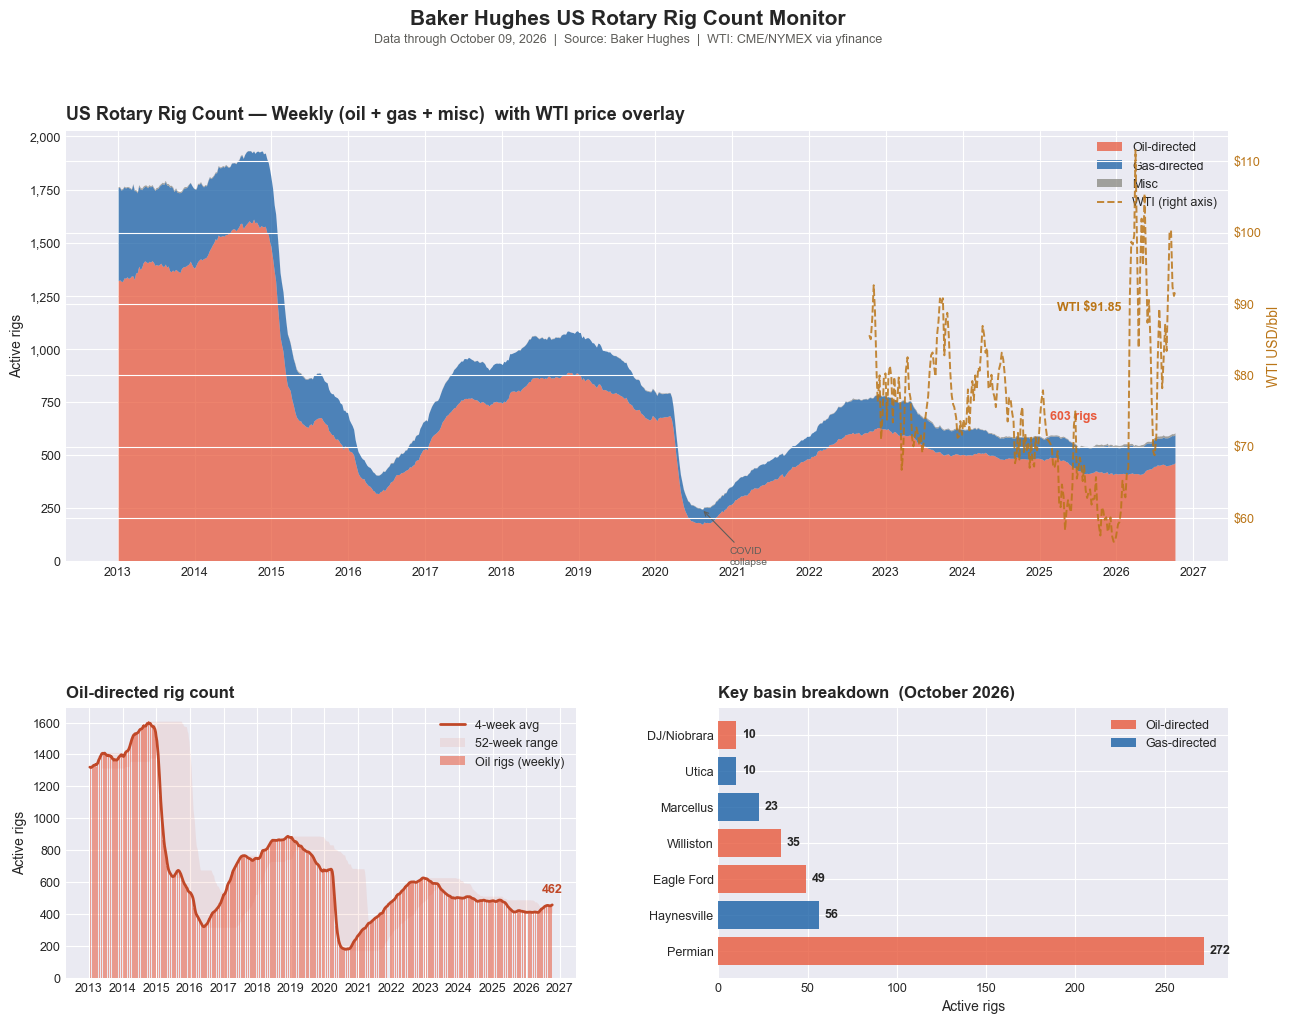


  Chart saved -> c:\Users\mackt\Python Projects\oil_gas_tools\charts\rig_count_monitor_October_09_2026.png


In [6]:
# ============================================================
# CELL 6 — Three-panel rig count chart
# ============================================================
# Layout (GridSpec):
#   Top (full width) : Total rig count stacked by type
#                      with WTI on secondary y-axis
#   Bottom-left      : Oil-directed rigs with 4-week avg
#   Bottom-right     : Basin breakdown bar chart (latest month)
# ─────────────────────────────────────────────────────────────

latest_m    = df_merged.iloc[-1]
latest_date = df_merged["date"].max().strftime("%B %d, %Y")

fig = plt.figure(figsize=(15, 11))
gs  = GridSpec(
    2, 2,
    figure        = fig,
    hspace        = 0.42,
    wspace        = 0.28,
    height_ratios = [1.6, 1],
)

ax1  = fig.add_subplot(gs[0, :])   # full-width top
ax2  = fig.add_subplot(gs[1, 0])   # bottom-left
ax3  = fig.add_subplot(gs[1, 1])   # bottom-right
ax1b = ax1.twinx()                 # WTI secondary axis

# ── Panel 1: Stacked rig count + WTI overlay ─────────────────
oil_vals  = df_merged["oil_rigs"].fillna(0)
gas_vals  = df_merged["gas_rigs"].fillna(0)
misc_vals = df_merged["misc_rigs"].fillna(0)

ax1.stackplot(
    df_merged["date"],
    oil_vals, gas_vals, misc_vals,
    labels = ["Oil-directed", "Gas-directed", "Misc"],
    colors = ["#E8593C", "#185FA5", "#888780"],
    alpha  = 0.75,
)

# WTI on secondary axis
ax1b.plot(
    df_merged["date"],
    df_merged["wti"],
    color     = "#BA7517",
    linewidth = 1.4,
    linestyle = "--",
    alpha     = 0.85,
    label     = "WTI (right axis)",
    zorder    = 5,
)

# Annotate latest total
ax1.annotate(
    f"{latest_m['total_rigs']:.0f} rigs",
    xy         = (df_merged["date"].iloc[-1],
                  latest_m["total_rigs"]),
    xytext     = (-90, 10),
    textcoords = "offset points",
    fontsize   = 9,
    color      = "#E8593C",
    fontweight = "bold",
)

# Annotate latest WTI
ax1b.annotate(
    f"WTI ${latest_m['wti']:.2f}",
    xy         = (df_merged["date"].iloc[-1],
                  latest_m["wti"]),
    xytext     = (-85, -14),
    textcoords = "offset points",
    fontsize   = 9,
    color      = "#BA7517",
    fontweight = "bold",
)

# Annotate COVID collapse
covid_date = pd.Timestamp("2020-08-01")
covid_row  = df_merged[
    df_merged["date"] >= covid_date
].iloc[0]
ax1.annotate(
    "COVID\ncollapse",
    xy         = (covid_row["date"], covid_row["total_rigs"]),
    xytext     = (20, -40),
    textcoords = "offset points",
    fontsize   = 7.5,
    color      = "#5F5E5A",
    arrowprops = dict(arrowstyle="->",
                      color="#5F5E5A",
                      lw=0.8),
)

ax1.set_title(
    "US Rotary Rig Count — Weekly (oil + gas + misc)  "
    "with WTI price overlay",
    fontsize=13, fontweight="bold", loc="left", pad=8,
)
ax1.set_ylabel("Active rigs", fontsize=10)
ax1b.set_ylabel("WTI USD/bbl", fontsize=10,
                color="#BA7517")
ax1.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax1b.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"${x:.0f}"))
ax1b.tick_params(axis="y", labelcolor="#BA7517",
                 labelsize=9)
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.tick_params(axis="both", labelsize=9)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax1b.get_legend_handles_labels()
ax1.legend(
    lines1 + lines2, labels1 + labels2,
    fontsize=9, loc="upper right",
    framealpha=0.85, edgecolor="none",
)

# ── Panel 2: Oil rig count with 4-week avg ────────────────────
ax2.bar(
    df_merged["date"],
    df_merged["oil_rigs"],
    width  = 5,
    color  = "#E8593C",
    alpha  = 0.55,
    label  = "Oil rigs (weekly)",
    zorder = 3,
)
ax2.plot(
    df_merged["date"],
    df_merged["oil_4wk_avg"],
    color     = "#c04828",
    linewidth = 2.0,
    label     = "4-week avg",
    zorder    = 4,
)
ax2.fill_between(
    df_merged["date"],
    df_merged["oil_52w_low"],
    df_merged["oil_52w_high"],
    alpha     = 0.10,
    color     = "#E8593C",
    linewidth = 0,
    label     = "52-week range",
)

# Annotate latest
ax2.annotate(
    f"{latest_m['oil_rigs']:.0f}",
    xy         = (df_merged["date"].iloc[-1],
                  latest_m["oil_rigs"]),
    xytext     = (0, 8),
    textcoords = "offset points",
    ha         = "center",
    fontsize   = 9,
    color      = "#c04828",
    fontweight = "bold",
)

ax2.set_title(
    "Oil-directed rig count",
    fontsize=12, fontweight="bold", loc="left", pad=8,
)
ax2.set_ylabel("Active rigs", fontsize=10)
ax2.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{x:.0f}"))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax2.xaxis.set_major_locator(mdates.YearLocator())
ax2.tick_params(axis="both", labelsize=9)
ax2.legend(fontsize=9, loc="upper right",
           framealpha=0.85, edgecolor="none")

# ── Panel 3: Basin breakdown (latest month) ───────────────────
basin_cols       = [c for c in df_basins.columns
                    if c != "date"]
latest_basin_row = df_basins.iloc[-1]
latest_basin_dt  = (df_basins["date"].max()
                    .strftime("%B %Y"))

basin_labels = []
basin_values = []
for basin in basin_cols:
    val = latest_basin_row.get(basin, 0)
    if not pd.isna(val) and val > 0:
        basin_labels.append(basin)
        basin_values.append(float(val))

# Sort descending
sorted_pairs = sorted(
    zip(basin_values, basin_labels), reverse=True
)
basin_values, basin_labels = zip(*sorted_pairs)

# Color by commodity type
gas_basins  = ["Haynesville", "Marcellus", "Utica"]
colors_bar  = [
    "#185FA5" if label in gas_basins else "#E8593C"
    for label in basin_labels
]

bars = ax3.barh(
    basin_labels,
    basin_values,
    color = colors_bar,
    alpha = 0.8,
)

ax3.set_xlabel("Active rigs", fontsize=10)
ax3.set_title(
    f"Key basin breakdown  ({latest_basin_dt})",
    fontsize=12, fontweight="bold", loc="left", pad=8,
)
ax3.xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{x:.0f}"))
ax3.tick_params(axis="both", labelsize=9)

for bar, val in zip(bars, basin_values):
    ax3.annotate(
        f"{val:.0f}",
        xy         = (val,
                      bar.get_y() + bar.get_height() / 2),
        xytext     = (4, 0),
        textcoords = "offset points",
        va         = "center",
        fontsize   = 9,
        fontweight = "bold",
    )

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#E8593C", alpha=0.8,
          label="Oil-directed"),
    Patch(facecolor="#185FA5", alpha=0.8,
          label="Gas-directed"),
]
ax3.legend(
    handles    = legend_elements,
    fontsize   = 9,
    loc        = "upper right",
    framealpha = 0.85,
    edgecolor  = "none",
)

# ── Figure-level annotations ──────────────────────────────────
fig.suptitle(
    "Baker Hughes US Rotary Rig Count Monitor",
    fontsize=15, fontweight="bold", y=0.99,
)
fig.text(
    0.5, 0.96,
    f"Data through {latest_date}  |  "
    f"Source: Baker Hughes  |  "
    f"WTI: CME/NYMEX via yfinance",
    ha="center", fontsize=9, color="#5F5E5A",
)

# ── Save and show ─────────────────────────────────────────────
chart_name = (
    f"rig_count_monitor_"
    f"{latest_date.replace(' ','_').replace(',','')}.png"
)
chart_path = CHART_DIR / chart_name
plt.savefig(chart_path, dpi=150, bbox_inches="tight",
            facecolor="white")
plt.show()
print(f"\n  Chart saved -> {chart_path}")

In [7]:
# ============================================================
# CELL 7 — Signal dashboard and plain English summary
# ============================================================
# Prints structured dashboard:
#   Weekly rig count snapshot (total, oil, gas)
#   WoW and YoY changes
#   52-week range and position
#   Permian concentration
#   WTI price and lagged correlation
#   Production outlook signal
#   Cross-tool context from Tool 4 (futures curve)
#   Plain English paragraph
# ─────────────────────────────────────────────────────────────

latest_m    = df_merged.iloc[-1]
latest_date = df_merged["date"].max().strftime("%B %d, %Y")

# ── 52-week percentile position ───────────────────────────────
total_52w_range = (latest_m["total_52w_high"]
                   - latest_m["total_52w_low"])
total_52w_pct   = (
    (latest_m["total_rigs"] - latest_m["total_52w_low"])
    / total_52w_range * 100
    if total_52w_range > 0 else float("nan")
)

oil_52w_range = (latest_m["oil_52w_high"]
                 - latest_m["oil_52w_low"])
oil_52w_pct   = (
    (latest_m["oil_rigs"] - latest_m["oil_52w_low"])
    / oil_52w_range * 100
    if oil_52w_range > 0 else float("nan")
)

# ── Gas rig YoY ───────────────────────────────────────────────
# Build from df_merged directly using date-based approach
target_prior = latest_m["date"] - pd.Timedelta(days=365)
prior_row    = df_merged[
    df_merged["date"] <= target_prior + pd.Timedelta(days=10)
].iloc[-1] if len(df_merged[
    df_merged["date"] <= target_prior + pd.Timedelta(days=10)
]) > 0 else None

gas_yoy = (
    float(latest_m["gas_rigs"]) - float(prior_row["gas_rigs"])
    if prior_row is not None else float("nan")
)

# ── Cross-tool context from Tool 4 ───────────────────────────
t4_note  = "Tool 4 CSV not found — run futures_curve_monitor first"
t4_wti   = float("nan")
t4_wti_structure = "N/A"

curve_files = sorted(glob.glob(str(DATA_DIR / "futures_curve_*.csv")))
if curve_files:
    df_t4     = pd.read_csv(curve_files[-1],
                             parse_dates=["date"])
    t4_latest = df_t4.iloc[-1]
    t4_wti    = t4_latest.get("wti", float("nan"))
    t4_wti_z  = t4_latest.get("wti_roll_spread_z",
                               float("nan"))
    t4_wti_spr = t4_latest.get("wti_roll_spread",
                                float("nan"))
    t4_ng_spr  = t4_latest.get("ng_roll_spread",
                                float("nan"))

    if not pd.isna(t4_wti_z):
        if t4_wti_z > 1.5:
            t4_wti_structure = "steep backwardation"
        elif t4_wti_z > 0.5:
            t4_wti_structure = "moderate backwardation"
        elif t4_wti_z < -1.5:
            t4_wti_structure = "steep contango"
        elif t4_wti_z < -0.5:
            t4_wti_structure = "moderate contango"
        else:
            t4_wti_structure = "flat / mild backwardation"

    t4_note = (
        f"WTI ${t4_wti:.2f}/bbl  |  "
        f"Curve: {t4_wti_structure} "
        f"(M1-M2 {t4_wti_spr:+.2f}/bbl, "
        f"z={t4_wti_z:+.2f})  |  "
        f"NG M1-M2: {t4_ng_spr:+.3f}/MMbtu"
    )

# ── WTI-to-rig forward signal ─────────────────────────────────
# Based on rolling correlation and current WTI level
# If WTI > $80 and rolling corr > 0.4:
#   expect rig stabilization/recovery in 16-20 weeks
wti_forward_note = ""
if (not pd.isna(latest_m["wti"]) and
    not pd.isna(latest_roll_corr)):
    if latest_m["wti"] > 80 and latest_roll_corr > 0.4:
        import datetime as dt2
        fwd_weeks   = 16
        fwd_date    = (df_merged["date"].max()
                       + pd.Timedelta(weeks=fwd_weeks))
        wti_forward_note = (
            f"WTI at ${latest_m['wti']:.2f} with "
            f"+{latest_roll_corr:.2f} rolling corr implies "
            f"rig stabilization possible by "
            f"~{fwd_date.strftime('%B %Y')}"
        )
    elif latest_m["wti"] < 60:
        wti_forward_note = (
            f"WTI below $60 — rig count likely to "
            f"accelerate lower in coming months"
        )
    else:
        wti_forward_note = (
            f"WTI at ${latest_m['wti']:.2f} — "
            f"rig count direction mixed"
        )

# ── Print dashboard ───────────────────────────────────────────
prod_signal = rig_signal(latest_m["total_yoy"])

print("=" * 62)
print("BAKER HUGHES RIG COUNT DASHBOARD")
print(f"Data through {latest_date}")
print("=" * 62)
print(f"""
  US TOTAL ROTARY RIG COUNT
  {'─' * 54}
  Current total    : {latest_m['total_rigs']:.0f} rigs
  Week-on-week     : {latest_m['total_rigs_wow']:+.0f} rigs
  Year-on-year     : {latest_m['total_yoy']:+.0f} rigs
  52-week range    : {latest_m['total_52w_low']:.0f} – {latest_m['total_52w_high']:.0f}
  52-week position : {total_52w_pct:.0f} percentile

  OIL-DIRECTED
  {'─' * 54}
  Current oil rigs : {latest_m['oil_rigs']:.0f} rigs
  Week-on-week     : {latest_m['oil_rigs_wow']:+.0f} rigs
  Year-on-year     : {latest_m['oil_yoy']:+.0f} rigs
  52-week range    : {latest_m['oil_52w_low']:.0f} – {latest_m['oil_52w_high']:.0f}
  52-week position : {oil_52w_pct:.0f} percentile
  Permian share    : {latest_m['permian_share']:.0f}% of oil rigs

  GAS-DIRECTED
  {'─' * 54}
  Current gas rigs : {latest_m['gas_rigs']:.0f} rigs
  Year-on-year     : {gas_yoy:+.0f} rigs

  WTI PRICE & LAG SIGNAL
  {'─' * 54}
  WTI current      : ${latest_m['wti']:.2f}/bbl
  Rolling corr     : {latest_roll_corr:+.3f}  (WTI lag 16wk, 3yr window)
  Forward signal   : {wti_forward_note}

  PRODUCTION OUTLOOK
  {'─' * 54}
  Signal           : {prod_signal}
""")

# ── Plain English summary ─────────────────────────────────────
yoy_dir     = "above" if latest_m["total_yoy"] >= 0 else "below"
oil_yoy_dir = "above" if latest_m["oil_yoy"] >= 0 else "below"

print("=" * 62)
print("  PLAIN ENGLISH SUMMARY")
print("=" * 62)
print(f"""
  As of {latest_date}, the US Baker Hughes rotary rig
  count stood at {latest_m['total_rigs']:.0f} active rigs —
  {abs(latest_m['total_yoy']):.0f} rigs {yoy_dir} the same week
  last year. Oil-directed rigs totaled {latest_m['oil_rigs']:.0f},
  {abs(latest_m['oil_yoy']):.0f} {oil_yoy_dir} year-on-year, with
  the Permian Basin accounting for {latest_m['permian_share']:.0f}%
  of all oil-directed activity.

  Gas-directed rigs stood at {latest_m['gas_rigs']:.0f},
  {abs(gas_yoy):.0f} {'above' if gas_yoy >= 0 else 'below'}
  year-on-year — reflecting {'rising' if gas_yoy >= 0 else 'falling'}
  gas drilling activity driven by LNG export demand
  and Henry Hub price signals.

  {wti_forward_note}.

  Production outlook: {prod_signal}.
  Rig count is a leading indicator — current activity
  translates to production changes in approximately
  6-9 months.
""")

print("=" * 62)
print("  CROSS-TOOL CONTEXT")
print("=" * 62)
print(f"""
  Tool 4 — Futures curve:
  {t4_note}

  Interpretation:
  WTI in {t4_wti_structure} signals near-term crude
  {'tightness — broadly supportive of drilling activity' if 'backwardation' in t4_wti_structure else 'oversupply — headwind for new drilling decisions'}.
  The 16-week lag implies drilling decisions made today
  reflect operator sentiment toward current WTI prices.
""")
print("=" * 62)

BAKER HUGHES RIG COUNT DASHBOARD
Data through October 09, 2026

  US TOTAL ROTARY RIG COUNT
  ──────────────────────────────────────────────────────
  Current total    : 603 rigs
  Week-on-week     : +5 rigs
  Year-on-year     : +56 rigs
  52-week range    : 542 – 603
  52-week position : 100 percentile

  OIL-DIRECTED
  ──────────────────────────────────────────────────────
  Current oil rigs : 462 rigs
  Week-on-week     : +6 rigs
  Year-on-year     : +44 rigs
  52-week range    : 406 – 462
  52-week position : 100 percentile
  Permian share    : 59% of oil rigs

  GAS-DIRECTED
  ──────────────────────────────────────────────────────
  Current gas rigs : 132 rigs
  Year-on-year     : +11 rigs

  WTI PRICE & LAG SIGNAL
  ──────────────────────────────────────────────────────
  WTI current      : $91.85/bbl
  Rolling corr     : +0.624  (WTI lag 16wk, 3yr window)
  Forward signal   : WTI at $91.85 with +0.62 rolling corr implies rig stabilization possible by ~January 2027

  PRODUCTION 

In [8]:
# ============================================================
# CELL 8 — Save data and wrap up
# ============================================================
# Saves merged rig count + WTI dataset to CSV.
# Documents BH data maintenance workflow.
# Prints complete cross-tool refresh schedule.
# ─────────────────────────────────────────────────────────────

# ── Save merged dataset ───────────────────────────────────────
save_cols = [
    "date",
    "total_rigs", "oil_rigs", "gas_rigs", "misc_rigs",
    "total_4wk_avg", "oil_4wk_avg",
    "total_yoy", "oil_yoy",
    "total_52w_high", "total_52w_low",
    "oil_52w_high", "oil_52w_low",
    "wti", "wti_ma26",
    "rolling_corr_3yr",
]

# Add basin columns if present
basin_cols = [c for c in df_merged.columns
              if c in ["Permian","Eagle Ford","Haynesville",
                       "Marcellus","DJ/Niobrara",
                       "Williston","Utica"]]
save_cols += basin_cols
if "permian_share" in df_merged.columns:
    save_cols.append("permian_share")

save_cols = [c for c in save_cols if c in df_merged.columns]

csv_filename = (
    f"rig_count_"
    f"{latest_date.replace(' ','_').replace(',','')}.csv"
)
csv_path = DATA_DIR / csv_filename
df_merged[save_cols].to_csv(csv_path, index=False)
print(f"  Rig count data saved -> {csv_path.name}")

# ── Save commentary log ───────────────────────────────────────
commentary_path = DATA_DIR / "rig_count_commentary_log.txt"

# Build basin snapshot
basin_snapshot = ""
for basin in ["Permian", "Eagle Ford", "Haynesville",
              "Marcellus", "DJ/Niobrara", "Williston", "Utica"]:
    if basin in df_merged.columns:
        val = latest_m.get(basin, float("nan"))
        if not pd.isna(val):
            basin_snapshot += f"  {basin:<18}: {val:.0f} rigs\n"

commentary_entry = f"""
{'=' * 62}
BAKER HUGHES RIG COUNT COMMENTARY
Run date  : {dt.date.today().strftime('%B %d, %Y')}
Data date : {latest_date}
{'=' * 62}

METRICS SNAPSHOT
  Total rigs       : {latest_m['total_rigs']:.0f}
  Week-on-week     : {latest_m['total_rigs_wow']:+.0f} rigs
  Year-on-year     : {latest_m['total_yoy']:+.0f} rigs
  52-week range    : {latest_m['total_52w_low']:.0f} - {latest_m['total_52w_high']:.0f}
  52-week position : {total_52w_pct:.0f} percentile

  Oil rigs         : {latest_m['oil_rigs']:.0f}
  WoW oil          : {latest_m['oil_rigs_wow']:+.0f} rigs
  YoY oil          : {latest_m['oil_yoy']:+.0f} rigs
  Permian share    : {latest_m['permian_share']:.0f}% of oil rigs

  Gas rigs         : {latest_m['gas_rigs']:.0f}
  YoY gas          : {gas_yoy:+.0f} rigs

  WTI price        : ${latest_m['wti']:.2f}/bbl
  Rolling corr     : {latest_roll_corr:+.3f} (WTI lag 16wk, 3yr window)
  Forward signal   : {wti_forward_note}
  Production sig   : {prod_signal}

KEY BASINS (latest month)
{basin_snapshot}
CROSS-TOOL CONTEXT
  Tool 4: {t4_note}
  Interpretation: WTI in {t4_wti_structure} signals near-term crude
  {'tightness — broadly supportive of drilling activity' if 'backwardation' in t4_wti_structure else 'oversupply — headwind for new drilling decisions'}.

PLAIN ENGLISH SUMMARY
  As of {latest_date}, the US Baker Hughes rotary rig
  count stood at {latest_m['total_rigs']:.0f} active rigs —
  {abs(latest_m['total_yoy']):.0f} rigs {yoy_dir} the same week last year.
  Oil-directed rigs totaled {latest_m['oil_rigs']:.0f},
  {abs(latest_m['oil_yoy']):.0f} {oil_yoy_dir} year-on-year, with
  the Permian Basin accounting for {latest_m['permian_share']:.0f}%
  of all oil-directed activity.
  Gas-directed rigs stood at {latest_m['gas_rigs']:.0f},
  {abs(gas_yoy):.0f} {'above' if gas_yoy >= 0 else 'below'} year-on-year.
  {wti_forward_note}.
  Production outlook: {prod_signal}.

"""

with open(commentary_path, "a", encoding="utf-8") as f:
    f.write(commentary_entry)

print(f"  Commentary logged -> {commentary_path.name}")

# ── Next release reminder ─────────────────────────────────────
today         = dt.date.today()
days_to_fri   = (4 - today.weekday()) % 7
next_friday   = today + dt.timedelta(
    days=days_to_fri if days_to_fri else 7
)

print()
print("=" * 62)
print("  TOOL 6 COMPLETE — Baker Hughes Rig Count Tracker")
print("=" * 62)
print(f"""
  What this notebook built:
  {'─' * 54}
  Loaded BH North America workbook (auto + manual fallback)
  Combined archive (2013-Aug 2025) + current (2024-present)
  Parsed NAM Weekly for weekly US rig count by type
  Parsed NAM Monthly for basin-level breakdown
  Deduplicated overlap period (Jan 2024-Aug 2025)
  Computed date-based YoY and rolling 4-week averages
  Calculated WTI-rig lagged correlation (3yr rolling)
  3-panel chart: full history, oil rigs, basin breakdown
  Signal dashboard with forward production outlook
  Cross-tool context from Tool 4 futures curve

  Next BH release:
  {'─' * 54}
  Date      : Friday {next_friday} ~1:00pm ET
  Frequency : Weekly (Fridays)

  Weekly refresh workflow:
  {'─' * 54}
  1. Go to: rigcount.bakerhughes.com/na-rig-count
  2. Download latest "North America Rig Count Report"
  3. Save as: data/BH_rig_count_manual.xlsx
             (overwrite previous file)
  4. Delete : data/BH_weekly_us_combined.csv
              data/BH_monthly_us_combined.csv
  5. Rerun  : Cells 1-8 (cache rebuilds in ~30 sec)

  Archive file reference:
  {'─' * 54}
  File    : 08-29-2025 North America Rig Count Report.xlsx
  Covers  : January 2013 - August 2025
  Purpose : Historical backfill (one-time, do not delete)
  Location: data/ folder

  Baker Hughes data notes:
  {'─' * 54}
  Format    : Long-format (one row per county/basin/type)
  NAM Weekly: aggregate by US_PublishDate for time series
  NAM Monthly: aggregate by Year+Month for basin breakdown
  Header row: 10 (0-indexed) in both sheets
  Sheet names may change with BH format updates — check
  Cell 2 print output if parsing fails after a new download

  Key thresholds:
  {'─' * 54}
  Total rigs > 700  : strong upstream activity
  Total rigs 500-700: moderate — production sustaining
  Total rigs < 500  : weak — production decline risk
  Permian share >50%: Permian dominating US growth
  Gas rigs YoY > 0  : gas supply growth ahead (6-9mo)

  Complete cross-tool refresh schedule:
  {'─' * 54}
  Monday               : Run Tool 2 (WTI/Brent monitor)
                         Run Tool 4 (futures curve)
  Wednesday 10:30am ET : Run Tool 1 (EIA crude inventory)
  Thursday 10:30am ET  : Run Tool 3 (EIA gas storage)
  Thursday afternoon   : Run Tool 4 (cross-tool update)
                         Run Tool 5 (LNG spread update)
  Friday 1:00pm ET     : Download BH Excel, run Tool 6
  Monthly (EIA lag)    : Run Tool 5 (new LNG volumes)
  Anytime              : Run Tool 4 (price/curve refresh)

  Data sources summary across all tools:
  {'─' * 54}
  Tool 1 : EIA API v2  /petroleum/stoc/wstk/data/
  Tool 2 : yfinance    CL=F, BZ=F
  Tool 3 : EIA API v2  /natural-gas/stor/wkly/data/
  Tool 4 : yfinance    CL=F, NG=F, CLM26, NGM26
  Tool 5 : EIA API v2  /natural-gas/move/expc/data/
           yfinance    NG=F, TTF=F, EURUSD=X
  Tool 6 : Baker Hughes Excel (weekly manual download)
           yfinance    CL=F (WTI overlay)
""")
print("=" * 62)

  Rig count data saved -> rig_count_October_09_2026.csv
  Commentary logged -> rig_count_commentary_log.txt

  TOOL 6 COMPLETE — Baker Hughes Rig Count Tracker

  What this notebook built:
  ──────────────────────────────────────────────────────
  Loaded BH North America workbook (auto + manual fallback)
  Combined archive (2013-Aug 2025) + current (2024-present)
  Parsed NAM Weekly for weekly US rig count by type
  Parsed NAM Monthly for basin-level breakdown
  Deduplicated overlap period (Jan 2024-Aug 2025)
  Computed date-based YoY and rolling 4-week averages
  Calculated WTI-rig lagged correlation (3yr rolling)
  3-panel chart: full history, oil rigs, basin breakdown
  Signal dashboard with forward production outlook
  Cross-tool context from Tool 4 futures curve

  Next BH release:
  ──────────────────────────────────────────────────────
  Date      : Friday 2026-10-16 ~1:00pm ET
  Frequency : Weekly (Fridays)

  Weekly refresh workflow:
  ─────────────────────────────────────────